# 01 · Ionic ratio scatter plots (Figure 4, SM1, SM2)

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development, 101706. https://doi.org/10.1016/j.gsd.2026.101706

**What this notebook does**

Binary ionic ratio plots in meq/L that identify the main water-rock interaction processes (halite, gypsum and carbonate dissolution, silicate weathering, cation exchange). Samples from this study are drawn as filled colored symbols by water type, and literature samples as open gray symbols by source.

| Panel | Plot | Article |
|---|---|---|
| (a) | Na⁺ vs Cl⁻ | Figure 4a |
| (b) | Ca²⁺ vs SO₄²⁻ | Figure 4b |
| (c) | (Ca²⁺+Mg²⁺) vs (HCO₃⁻+SO₄²⁻) | Figure 4c |
| (d) | HCO₃⁻ vs Na⁺ | Figure 4d |
| (e) | Ca²⁺/Mg²⁺ vs Ca²⁺ | Figure 4e and Figure SM1 |
| (f) | CAI-I vs CAI-II | Figure 4f and Figure SM2 |
| (g) | HCO₃⁻ vs Ca²⁺ | Figure 4g |
| (h) | (Na⁺+K⁺−Cl⁻) vs (Ca²⁺+Mg²⁺−HCO₃⁻−SO₄²⁻) | Figure 4h |

Each panel and the shared legend are saved separately; Figure 4 is their 3 × 3 assembly.

| | |
|---|---|
| **Input** | `data/All_data1.xlsx` (all 540 samples; each plot uses the samples with the ions it needs) |
| **Figures** | `outputs/figures/Figure4_panels/Figure4a_...` to `Figure4h_...` and `Figure4_legend`; `outputs/figures/SM01_CaMg_ratio_vs_Ca`, `SM02_CAI_indices` |
| **Next notebook** | `03_PCA_SOM_HCA/01_PCA_SOM_training.ipynb` |

### <font color='orange'> **1) Packages, settings and paths** </font>

In [1]:
# ── Data handling ──────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ──────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
from matplotlib.ticker import LogLocator, LogFormatter

# ── Utilities ──────────────────────────────────────────────────────────────
import gc
import shutil
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Display options ────────────────────────────────────────────────────────
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.3f}'.format)

# ── Global plot style ──────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi'        : 150,
    'font.family'       : 'DejaVu Sans',
    'font.size'         : 10,
    'axes.titlesize'    : 11,
    'axes.labelsize'    : 10,
    'legend.fontsize'   : 8,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
})

# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DATA_FILE   = ROOT / "data" / "All_data1.xlsx"
DIR_FIGURES = ROOT / "outputs" / "figures"
DIR_PANELS  = DIR_FIGURES / "Figure4_panels"
DIR_PANELS.mkdir(parents=True, exist_ok=True)

EXPORT_DPI = 600   # journal resolution
COUNTS = {}        # points plotted per panel (this study, literature), checked at the end

print(f"Data file : {DATA_FILE.relative_to(ROOT)}  (exists: {DATA_FILE.is_file()})")

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Data file : data\All_data1.xlsx  (exists: True)


### <font color='orange'> **2) Load the data** </font>

Only the identifiers and the ions used in the plots are kept. Water types are labelled as in Figure 4: groundwater samples are shown as **Well**, tributaries are merged with **Stream**, and the Zaraba canal is shown as **Canal (Zaraba)**.

In [2]:
df = pd.read_excel(DATA_FILE, sheet_name="Sheet1")
COLS = ["Reference", "SampleID", "Type",
        "Ca (mg/L)", "Mg (mg/L)", "Na (mg/L)", "K (mg/L)",
        "HCO3 (mg/L)", "CO3 (mg/L)", "Cl (mg/L)", "SO4 (mg/L)", "NO3 (mg/L)"]
df = df[COLS].copy()

# Water-type labels used in Figure 4
df["Type"] = df["Type"].replace({"Groundwater": "Well",
                                 "Tributary": "Stream",
                                 "Zaraba": "Canal (Zaraba)"})

print(f"Shape      : {df.shape[0]} rows × {df.shape[1]} columns")
print(f"References : {df['Reference'].nunique()} sources")
print()
print("Type counts:")
print(df["Type"].value_counts().to_string())

Shape      : 540 rows × 12 columns
References : 9 sources

Type counts:
Type
Well              339
Spring             78
Stream             49
Snow               37
Rain               21
Lac                11
Dam                 2
Irrigation          2
Canal (Zaraba)      1


### <font color='orange'> **3) Unit conversion (mg/L → meq/L)** </font>

In [3]:
# ── Convert mg/L → meq/L ───────────────────────────────────────────────────
df['Ca']   = df['Ca (mg/L)']   / 20.04
df['Mg']   = df['Mg (mg/L)']   / 12.15
df['Na']   = df['Na (mg/L)']   / 22.99
df['K']    = df['K (mg/L)']    / 39.10
df['HCO3'] = df['HCO3 (mg/L)'] / 61.02
df['Cl']   = df['Cl (mg/L)']   / 35.45
df['SO4']  = df['SO4 (mg/L)']  / 48.03
df['NO3']  = df['NO3 (mg/L)']  / 62.00

print('meq/L columns added ✓')
print(df[['Ca','Mg','Na','K','HCO3','Cl','SO4','NO3']].describe().round(3).to_string())

meq/L columns added ✓
           Ca      Mg      Na       K    HCO3      Cl     SO4     NO3
count 410.000 407.000 409.000 410.000 410.000 458.000 410.000 410.000
mean    4.989   5.118   4.869   5.973   4.754   5.068   3.186   6.873
std     3.467  34.112   7.790  19.121   2.006   8.354  10.300  26.756
min     0.045   0.003   0.004   0.000   0.066   0.006   0.001   0.000
25%     2.815   1.086   1.087   0.029   3.577   0.501   0.577   0.075
50%     4.242   2.363   2.539   0.053   4.804   2.014   1.258   0.191
75%     5.998   4.390   5.002   0.130   6.074   6.346   2.691   0.347
max    21.657 687.572  57.702 143.299  12.496  63.928 162.169 156.532


### <font color='orange'> **4) Plot style: this study vs literature** </font>

Bigger, bold labels so that the panels stay readable once assembled into Figure 4.

In [4]:
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

# ── Journal-quality rcParams: bigger, bold labels ───────────────────────
mpl.rcParams.update({
    'font.family'         : 'Arial',
    'font.weight'         : 'bold',
    'axes.linewidth'      : 1.2,
    'xtick.direction'     : 'in',
    'ytick.direction'     : 'in',
    'xtick.minor.visible' : True,
    'ytick.minor.visible' : True,
    'xtick.labelsize'     : 16,
    'ytick.labelsize'     : 16,
    'axes.labelsize'      : 18,
    'axes.labelweight'    : 'bold',
    'axes.titlesize'      : 18,
    'axes.titleweight'    : 'bold',
    'legend.fontsize'     : 14,
    'figure.dpi'          : 100,
    'axes.spines.top'     : True,
    'axes.spines.right'   : True,
    'xtick.major.width'   : 1.2,
    'ytick.major.width'   : 1.2,
    'xtick.major.size'    : 6,
    'ytick.major.size'    : 6,
    'xtick.minor.size'    : 3,
    'ytick.minor.size'    : 3,
})

# ── Identity ─────────────────────────────────────────────────────────────
MY_REF = '(EL FARCHOUNI et al., 2025)'

# ── References WITHOUT hydrochemical data ──────────────────────────────
NO_HYDROCHEM = ['(Bouimouass et al., 2024)', '(Rhoujjati et al., 2021)']

# ── "This study" markers & colors ──────────────────────────────────
THIS_STYLE = {
    'Well'           : dict(marker='o', color='#1F77B4', label='Well'),
    'Spring'         : dict(marker='^', color='#2CA02C', label='Spring'),
    'Stream'         : dict(marker='*', color='#00B0F0', label='Stream'),
    'Dam'            : dict(marker='X', color='#9467BD', label='Dam'),
    'Lac'            : dict(marker='P', color='#8C564B', label='Lake'),
    'Canal (Zaraba)' : dict(marker='h', color='#E377C2', label='Canal (Zaraba)'),
}

# ── Literature markers ──────────────────────────────────────────────────
LIT_STYLE = {
    '(Boukhari et al., 2015)'   : dict(marker='o', color='#595959', label='Boukhari et al. (2015)'),
    '(Rochdane et al., 2015)'   : dict(marker='D', color='#595959', label='Rochdane et al. (2015)'),
    '(Bouimouass et al., 2020)' : dict(marker='s', color='#808080', label='Bouimouass et al. (2020)'),
    '(Kamal et al., 2021)'      : dict(marker='^', color='#808080', label='Kamal et al. (2021)'),
    '(Sahraoui et al., 2025)'   : dict(marker='h', color='#808080', label='Sahraoui et al. (2025)'),
    'Fakir'                     : dict(marker='*', color='#595959', label='Fakir'),
}

# ── FIXED dimensions ───────────────────────────────────────────────────
FIG_W, FIG_H = 7.5, 6.5
DISPLAY_W, DISPLAY_H = 9.0, 7.5

SUBPLOT_LEFT   = 0.18
SUBPLOT_RIGHT  = 0.96
SUBPLOT_BOTTOM = 0.16
SUBPLOT_TOP    = 0.96

MS_THIS = 110
MS_LIT  = 75

def scatter_panel(ax, xvar, yvar, log_scale=False):
    plot_df = df.dropna(subset=[xvar, yvar]).copy()
    plot_df = plot_df[~plot_df['Reference'].isin(NO_HYDROCHEM)]
    if log_scale:
        plot_df = plot_df[(plot_df[xvar] > 0) & (plot_df[yvar] > 0)]
    lit  = plot_df[plot_df['Reference'] != MY_REF]
    mine = plot_df[plot_df['Reference'] == MY_REF]

    for ref, sty in LIT_STYLE.items():
        sub = lit[lit['Reference'] == ref]
        if sub.empty: continue
        ax.scatter(sub[xvar], sub[yvar], marker=sty['marker'], s=MS_LIT,
                   facecolors='none', edgecolors=sty['color'],
                   linewidths=1.4, alpha=0.7, zorder=2)

    for typ, sty in THIS_STYLE.items():
        sub = mine[mine['Type'] == typ]
        if sub.empty: continue
        ax.scatter(sub[xvar], sub[yvar], marker=sty['marker'], s=MS_THIS,
                   color=sty['color'], edgecolors='white',
                   linewidths=0.8, alpha=0.9, zorder=3)

    if log_scale:
        ax.set_xscale('log')
        ax.set_yscale('log')
    return mine, lit

def plain_fmt(x, pos):
    if x == 0: return '0'
    return f'{x:g}' if abs(x) < 1000 else f'{int(x):,}'

def save_fig(fig, folder, filename):
    fig.set_size_inches(DISPLAY_W, DISPLAY_H)
    fig.subplots_adjust(left=SUBPLOT_LEFT, right=SUBPLOT_RIGHT,
                        bottom=SUBPLOT_BOTTOM, top=SUBPLOT_TOP)
    plt.show()
    fig.set_size_inches(FIG_W, FIG_H)
    fig.subplots_adjust(left=SUBPLOT_LEFT, right=SUBPLOT_RIGHT,
                        bottom=SUBPLOT_BOTTOM, top=SUBPLOT_TOP)
    for fmt in ['png']:
        fig.savefig(Path(folder) / f'{filename}.{fmt}',
                    format=fmt, dpi=EXPORT_DPI, facecolor='white')
    print(f'Saved: {filename}  ->  {Path(folder).relative_to(ROOT)}')
    plt.close(fig)
    gc.collect()

print('Style defined OK')
print(f'Export: {FIG_W}" x {FIG_H}" @ {EXPORT_DPI} dpi -> {int(FIG_W*EXPORT_DPI)} x {int(FIG_H*EXPORT_DPI)} px')

Style defined OK
Export: 7.5" x 6.5" @ 600 dpi -> 4500 x 3900 px


---
## <font color='orange'> **5) Figure 4 panels** </font>

### (a) Na⁺ vs Cl⁻

**Interpretation:** The 1:1 equiline represents halite dissolution (Na⁺ = Cl⁻). Samples plotting above indicate an excess of Na⁺ from silicate weathering or cation exchange; samples below suggest Cl⁻ enrichment from sources other than halite.

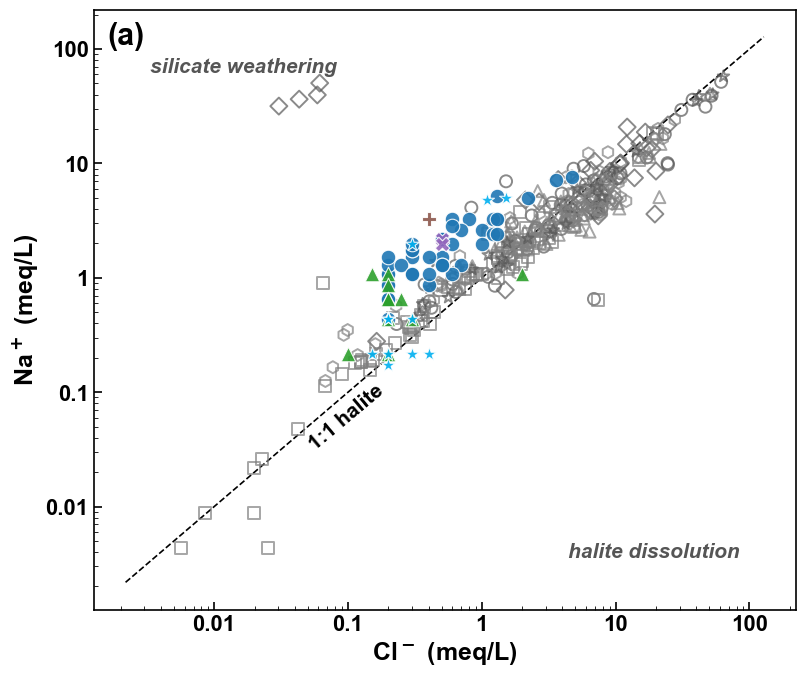

Saved: Figure4a_Na_vs_Cl  ->  outputs\figures\Figure4_panels
This study: 69 pts  |  Literature: 340 pts


In [5]:
# ── (a) Na⁺ vs Cl⁻ ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(DISPLAY_W, DISPLAY_H))

mine, lit = scatter_panel(ax, 'Cl', 'Na', log_scale=True)

# ── 1:1 equiline (halite dissolution) ─────────────────────────────────────
all_vals = pd.concat([mine['Cl'], mine['Na'], lit['Cl'], lit['Na']]).dropna()
lo, hi = all_vals.min() * 0.5, all_vals.max() * 2
ax.plot([lo, hi], [lo, hi], color='black', ls='--', lw=1.2, zorder=1)

# ── Line label INSIDE the plot area ───────────────────────────────────────
ax.text(0.36, 0.26, '1:1 halite', fontsize=15, fontweight='bold', color='black',
        rotation=40, transform=ax.transAxes, ha='center', va='bottom')

# ── Zone annotations ──────────────────────────────────────────────────────
ax.text(0.08, 0.92, 'silicate weathering', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='left', va='top')
ax.text(0.92, 0.08, 'halite dissolution', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='right', va='bottom')

# ── Axis labels ───────────────────────────────────────────────────────────
ax.set_xlabel(r'Cl$^-$ (meq/L)')
ax.set_ylabel(r'Na$^+$ (meq/L)')
ax.xaxis.set_major_formatter(FuncFormatter(plain_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(plain_fmt))

# ── Subplot label ─────────────────────────────────────────────────────────
ax.text(0.02, 0.98, '(a)', transform=ax.transAxes, fontsize=22,
        fontweight='bold', va='top', ha='left')

save_fig(fig, DIR_PANELS, 'Figure4a_Na_vs_Cl')
print(f'This study: {len(mine)} pts  |  Literature: {len(lit)} pts')
COUNTS['a'] = (len(mine), len(lit))

---
### <font color='Orange'> (b) Ca²⁺ vs SO₄²⁻ </font>

**Interpretation:** The 1:1 equiline represents gypsum dissolution (Ca²⁺ = SO₄²⁻). Samples above the line indicate excess Ca²⁺ from calcite or dolomite dissolution; samples to the right suggest excess SO₄²⁻ from pyrite oxidation or agricultural inputs.

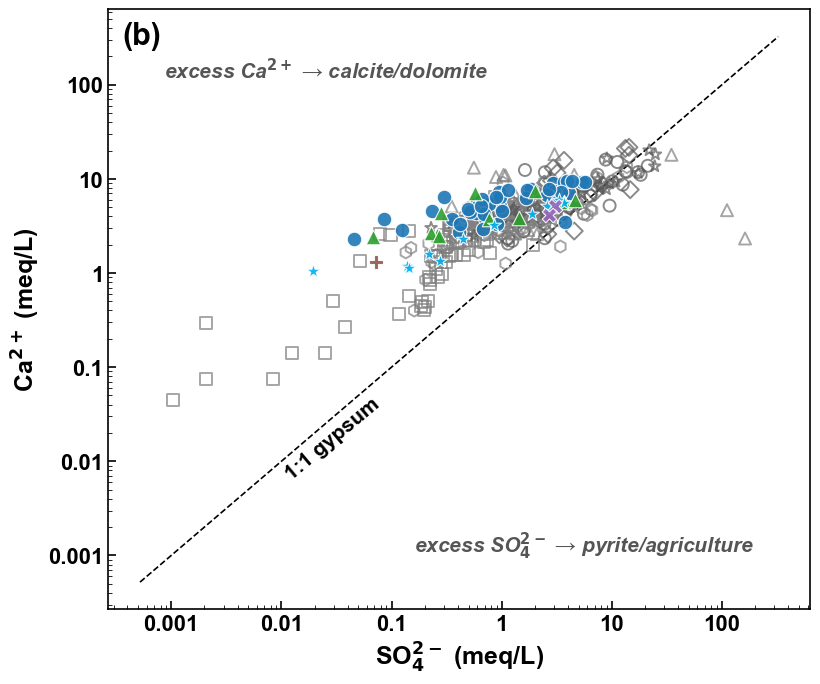

Saved: Figure4b_Ca_vs_SO4  ->  outputs\figures\Figure4_panels
This study: 69 pts  |  Literature: 341 pts


In [6]:
# ── (b) Ca²⁺ vs SO₄²⁻  (meq/L) ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(DISPLAY_W, DISPLAY_H))

mine, lit = scatter_panel(ax, 'SO4', 'Ca', log_scale=True)

# ── 1:1 equiline (gypsum dissolution) ─────────────────────────────────────
all_vals = pd.concat([mine['SO4'], mine['Ca'], lit['SO4'], lit['Ca']]).dropna()
lo, hi = all_vals.min() * 0.5, all_vals.max() * 2
ax.plot([lo, hi], [lo, hi], color='black', ls='--', lw=1.2, zorder=1)

# ── Line label INSIDE the plot area ───────────────────────────────────────
ax.text(0.32, 0.21, '1:1 gypsum', fontsize=15, fontweight='bold', color='black',
        rotation=40, transform=ax.transAxes, ha='center', va='bottom')

# ── Zone annotations ──────────────────────────────────────────────────────
ax.text(0.08, 0.92, r'excess Ca$^{2+}$ → calcite/dolomite', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='left', va='top')
ax.text(0.92, 0.08, r'excess SO$_4^{2-}$ → pyrite/agriculture', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='right', va='bottom')

# ── Axis labels ───────────────────────────────────────────────────────────
ax.set_xlabel(r'SO$_4^{2-}$ (meq/L)')
ax.set_ylabel(r'Ca$^{2+}$ (meq/L)')
ax.xaxis.set_major_formatter(FuncFormatter(plain_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(plain_fmt))

# ── Subplot label ─────────────────────────────────────────────────────────
ax.text(0.02, 0.98, '(b)', transform=ax.transAxes, fontsize=22,
        fontweight='bold', va='top', ha='left')

save_fig(fig, DIR_PANELS, 'Figure4b_Ca_vs_SO4')
print(f'This study: {len(mine)} pts  |  Literature: {len(lit)} pts')
COUNTS['b'] = (len(mine), len(lit))

---
### <font color='Orange'> (c) (Ca²⁺ + Mg²⁺) vs (HCO₃⁻ + SO₄²⁻) </font>

**Interpretation:** The 1:1 equiline (Fisher & Mullican, 1997) represents the balance between carbonate/gypsum dissolution and divalent cation supply. Samples near the line indicate carbonate + gypsum weathering dominance. Samples plotting above the line suggest an excess of Ca²⁺ + Mg²⁺, pointing to cation exchange releasing Ca/Mg into solution.

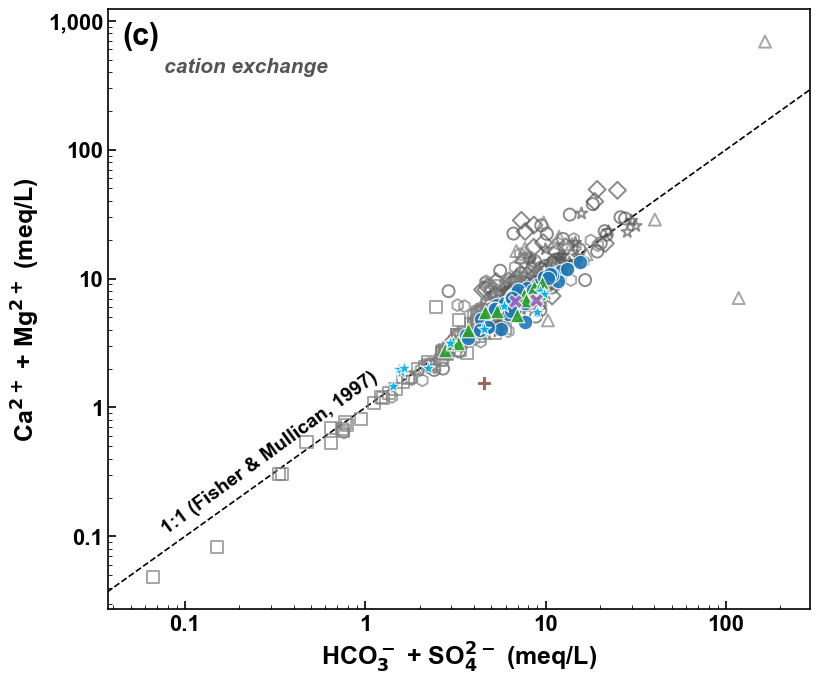

Saved: Figure4c_CaMg_vs_HCO3SO4  ->  outputs\figures\Figure4_panels
This study: 69 pts  |  Literature: 338 pts


In [7]:
# ── (c) (Ca²⁺+Mg²⁺) vs (HCO₃⁻+SO₄²⁻)  (meq/L) ──────────────────────────
df['Ca_Mg']     = df['Ca'] + df['Mg']
df['HCO3_SO4']  = df['HCO3'] + df['SO4']

fig, ax = plt.subplots(figsize=(DISPLAY_W, DISPLAY_H))

mine, lit = scatter_panel(ax, 'HCO3_SO4', 'Ca_Mg', log_scale=True)

# ── 1:1 equiline (Fisher & Mullican 1997) ─────────────────────────────────
all_vals = pd.concat([mine['HCO3_SO4'], mine['Ca_Mg'],
                      lit['HCO3_SO4'],  lit['Ca_Mg']]).dropna()
lo = all_vals.min() * 0.7
hi = all_vals.max() * 1.5
ax.plot([lo, hi], [lo, hi], color='black', ls='--', lw=1.2, zorder=1)

# ── Zoom to data range ────────────────────────────────────────────────────
pad = 0.25
x_all = pd.concat([mine['HCO3_SO4'], lit['HCO3_SO4']]).dropna()
y_all = pd.concat([mine['Ca_Mg'], lit['Ca_Mg']]).dropna()
ax.set_xlim(10**(np.log10(x_all.min()) - pad), 10**(np.log10(x_all.max()) + pad))
ax.set_ylim(10**(np.log10(y_all.min()) - pad), 10**(np.log10(y_all.max()) + pad))

# ── Line label INSIDE the plot area ───────────────────────────────────────
ax.text(0.23, 0.12, '1:1 (Fisher & Mullican, 1997)', fontsize=14, fontweight='bold', color='black',
        rotation=36.2, transform=ax.transAxes, ha='center', va='bottom')

# ── Zone annotation ───────────────────────────────────────────────────────
ax.text(0.08, 0.92, 'cation exchange', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='left', va='top')

# ── Axis labels ───────────────────────────────────────────────────────────
ax.set_xlabel(r'HCO$_3^-$ + SO$_4^{2-}$ (meq/L)')
ax.set_ylabel(r'Ca$^{2+}$ + Mg$^{2+}$ (meq/L)')
ax.xaxis.set_major_formatter(FuncFormatter(plain_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(plain_fmt))

# ── Subplot label ─────────────────────────────────────────────────────────
ax.text(0.02, 0.98, '(c)', transform=ax.transAxes, fontsize=22,
        fontweight='bold', va='top', ha='left')

save_fig(fig, DIR_PANELS, 'Figure4c_CaMg_vs_HCO3SO4')
print(f'This study: {len(mine)} pts  |  Literature: {len(lit)} pts')
COUNTS['c'] = (len(mine), len(lit))

---
### <font color='Orange'> (d) HCO₃⁻ vs Na⁺ </font>

**Interpretation:** The Na⁺–HCO₃⁻ relationship helps identify silicate weathering. Albite dissolution yields a 1:1 Na⁺/HCO₃⁻ molar ratio. Samples near the 1:1 line indicate silicate weathering as the dominant Na⁺ source. Excess Na⁺ above the line suggests additional sources (halite, cation exchange); excess HCO₃⁻ points to carbonate dissolution.

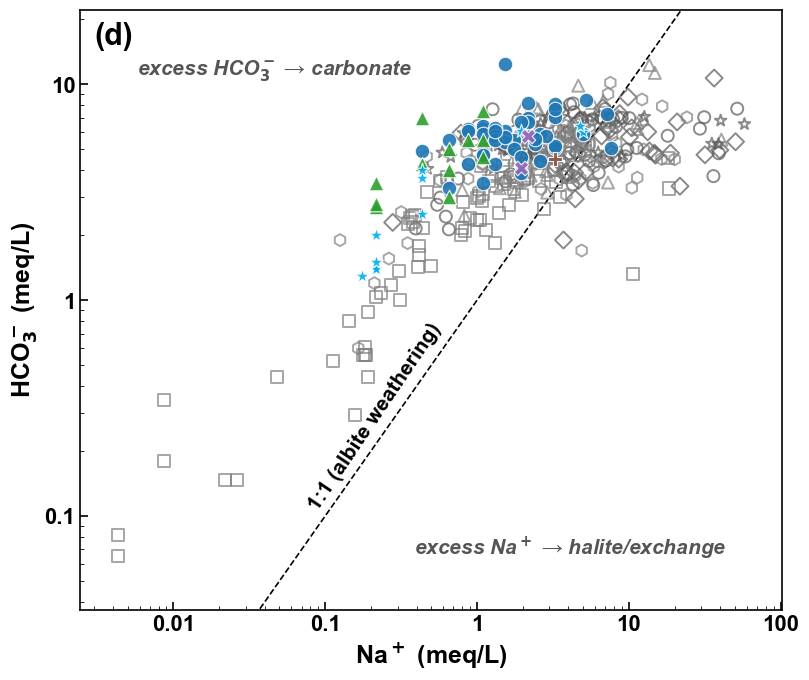

Saved: Figure4d_HCO3_vs_Na  ->  outputs\figures\Figure4_panels
This study: 69 pts  |  Literature: 340 pts


In [8]:
# ── (d) HCO₃⁻ vs Na⁺  (meq/L) ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(DISPLAY_W, DISPLAY_H))

mine, lit = scatter_panel(ax, 'Na', 'HCO3', log_scale=True)

# ── 1:1 equiline (silicate weathering - albite) ───────────────────────────
all_vals = pd.concat([mine['Na'], mine['HCO3'], lit['Na'], lit['HCO3']]).dropna()
lo, hi = all_vals.min() * 0.5, all_vals.max() * 2
ax.plot([lo, hi], [lo, hi], color='black', ls='--', lw=1.2, zorder=1)

# ── Zoom to data range ────────────────────────────────────────────────────
pad = 0.25
x_all = pd.concat([mine['Na'], lit['Na']]).dropna()
y_all = pd.concat([mine['HCO3'], lit['HCO3']]).dropna()
ax.set_xlim(10**(np.log10(x_all.min()) - pad), 10**(np.log10(x_all.max()) + pad))
ax.set_ylim(10**(np.log10(y_all.min()) - pad), 10**(np.log10(y_all.max()) + pad))

# ── Line label INSIDE the plot area ───────────────────────────────────────
ax.text(0.42, 0.16, '1:1 (albite weathering)', fontsize=15, fontweight='bold', color='black',
        rotation=56, transform=ax.transAxes, ha='center', va='bottom')

# ── Zone annotations ──────────────────────────────────────────────────────
ax.text(0.08, 0.92, r'excess HCO$_3^-$ → carbonate', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='left', va='top')
ax.text(0.92, 0.08, r'excess Na$^+$ → halite/exchange', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='right', va='bottom')

# ── Axis labels ───────────────────────────────────────────────────────────
ax.set_xlabel(r'Na$^+$ (meq/L)')
ax.set_ylabel(r'HCO$_3^-$ (meq/L)')
ax.xaxis.set_major_formatter(FuncFormatter(plain_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(plain_fmt))

# ── Subplot label ─────────────────────────────────────────────────────────
ax.text(0.02, 0.98, '(d)', transform=ax.transAxes, fontsize=22,
        fontweight='bold', va='top', ha='left')

save_fig(fig, DIR_PANELS, 'Figure4d_HCO3_vs_Na')
print(f'This study: {len(mine)} pts  |  Literature: {len(lit)} pts')
COUNTS['d'] = (len(mine), len(lit))

---
### <font color='Orange'> (e) Ca²⁺/Mg²⁺ vs Ca²⁺ (also Figure SM1) </font>

**Interpretation:** The Ca/Mg molar ratio discriminates carbonate mineral sources. Ca/Mg > 2 indicates calcite dissolution dominance. Ca/Mg ≈ 1 suggests dolomite dissolution. Values between 1 and 2 reflect mixed calcite–dolomite weathering. Very high ratios (>4) may indicate gypsum or silicate Ca sources with limited Mg input.

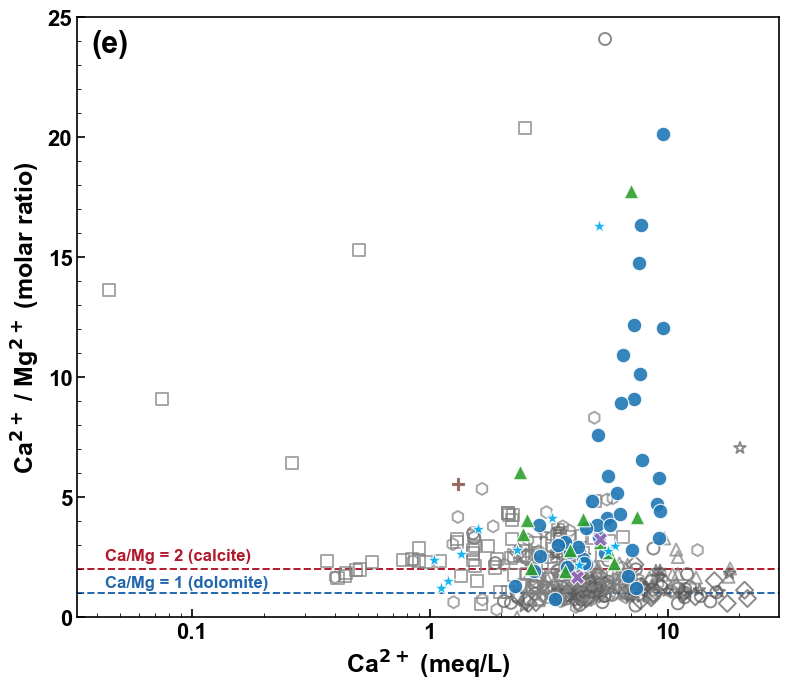

Saved: Figure4e_CaMg_ratio_vs_Ca  ->  outputs\figures\Figure4_panels
This study: 69 pts  |  Literature: 338 pts
Copied as Figure SM1: outputs/figures/SM01_CaMg_ratio_vs_Ca


In [9]:
# ── (e) Ca²⁺/Mg²⁺ vs Ca²⁺  (meq/L) ───────────────────────────────────────
df['Ca_Mg_ratio'] = np.where(df['Mg'] > 0, df['Ca'] / df['Mg'], np.nan)

fig, ax = plt.subplots(figsize=(DISPLAY_W, DISPLAY_H))

mine, lit = scatter_panel(ax, 'Ca', 'Ca_Mg_ratio', log_scale=False)

# ── Log scale on X only ───────────────────────────────────────────────────
ax.set_xscale('log')
ax.xaxis.set_major_formatter(FuncFormatter(plain_fmt))

# ── Zoom Y to useful range ────────────────────────────────────────────────
ax.set_ylim(0, 25)

# ── Reference lines ────────────────────────────────────────────────────────
ax.axhline(1, color='#2166AC', ls='--', lw=1.4, zorder=1)
ax.axhline(2, color='#B2182B', ls='--', lw=1.4, zorder=1)

# ── Zone labels - left side, next to lines ─────────────────────────────────
ax.text(0.04, 0.045, 'Ca/Mg = 1 (dolomite)', fontsize=12, fontweight='bold', color='#2166AC',
        transform=ax.transAxes, ha='left', va='bottom')
ax.text(0.04, 0.09, 'Ca/Mg = 2 (calcite)', fontsize=12, fontweight='bold', color='#B2182B',
        transform=ax.transAxes, ha='left', va='bottom')


# ── Axis labels ───────────────────────────────────────────────────────────
ax.set_xlabel(r'Ca$^{2+}$ (meq/L)')
ax.set_ylabel(r'Ca$^{2+}$ / Mg$^{2+}$ (molar ratio)')

# ── Subplot label ─────────────────────────────────────────────────────────
ax.text(0.02, 0.98, '(e)', transform=ax.transAxes, fontsize=22,
        fontweight='bold', va='top', ha='left')

save_fig(fig, DIR_PANELS, 'Figure4e_CaMg_ratio_vs_Ca')
print(f'This study: {len(mine)} pts  |  Literature: {len(lit)} pts')
COUNTS['e'] = (len(mine), len(lit))

# ── The same panel is Figure SM1 ─────────────────────────────────────────
for fmt in ['png']:
    shutil.copyfile(DIR_PANELS / f"Figure4e_CaMg_ratio_vs_Ca.{fmt}", DIR_FIGURES / f"SM01_CaMg_ratio_vs_Ca.{fmt}")
print("Copied as Figure SM1: outputs/figures/SM01_CaMg_ratio_vs_Ca")

---
### <font color='Orange'> **(f) CAI-I vs CAI-II (Schoeller, 1965), also Figure SM2** </font>

#### Chloro-Alkaline Indices

The **Chloro-Alkaline Indices** (CAI-I and CAI-II) were introduced by **Schoeller (1965)** to identify and quantify **ion exchange processes** between groundwater and the aquifer matrix. They are widely used in hydrochemistry (Li et al., 2013; Talib et al., 2019; Bouimouass et al., 2022).

#### Equations (all concentrations in meq/L):

$$\text{CAI-I} = \frac{\text{Cl}^- - (\text{Na}^+ + \text{K}^+)}{\text{Cl}^-}$$

$$\text{CAI-II} = \frac{\text{Cl}^- - (\text{Na}^+ + \text{K}^+)}{\text{HCO}_3^- + \text{SO}_4^{2-} + \text{CO}_3^{2-} + \text{NO}_3^-}$$

#### Interpretation:

| CAI-I & CAI-II | Process | Meaning |
|:-:|:-:|:--|
| **Both positive** | **Reverse ion exchange** | Na⁺ in groundwater is exchanged for Ca²⁺/Mg²⁺ on clay minerals. The aquifer matrix **takes up Na⁺** and **releases Ca²⁺/Mg²⁺**. |
| **Both negative** | **Direct cation exchange** | Ca²⁺/Mg²⁺ in groundwater is exchanged for Na⁺ on clay minerals. The aquifer matrix **releases Na⁺** and **takes up Ca²⁺/Mg²⁺**. |
| **Near zero** | **No significant exchange** | Chloride-alkali balance, no dominant exchange process. |

Sign convention as in Schoeller (1965) and Li et al. (2013): negative indices = direct cation exchange, positive indices = reverse ion exchange.

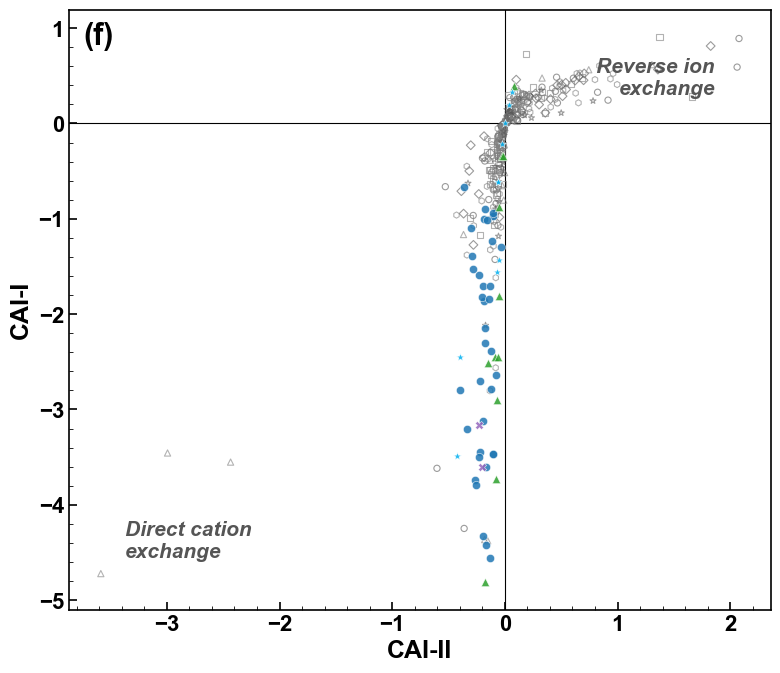

Saved: Figure4f_CAI-I_vs_CAI-II  ->  outputs\figures\Figure4_panels
This study: 59 pts  |  Literature: 298 pts  |  Excluded (outliers): 52
  This study: 59 pts - 4 positive (reverse ion exchange), 55 negative (direct cation exchange)
  Literature: 298 pts - 142 positive (reverse ion exchange), 156 negative (direct cation exchange)
Copied as Figure SM2: outputs/figures/SM02_CAI_indices


In [10]:
# ── (f) CAI-I vs CAI-II  (Schoeller, 1965) ────────────────────────────────
# Convert CO3 to meq/L (if available)
df['CO3'] = df['CO3 (mg/L)'] / 30.00  # CO3²⁻ meq = mg / (60.01/2)

# ── CAI-I = (Cl - (Na+K)) / Cl ────────────────────────────────────────────
numerator = df['Cl'] - (df['Na'] + df['K'])
df['CAI_I'] = np.where(df['Cl'] > 0, numerator / df['Cl'], np.nan)

# ── CAI-II = (Cl - (Na+K)) / (HCO3 + SO4 + CO3 + NO3) ────────────────────
denom = df['HCO3'] + df['SO4'] + df['CO3'].fillna(0) + df['NO3'].fillna(0)
df['CAI_II'] = np.where(denom > 0, numerator / denom, np.nan)

fig, ax = plt.subplots(figsize=(DISPLAY_W, DISPLAY_H))

# ── Exclude extreme values (|CAI| > 5) so the main cloud stays readable ───
CAI_THRESHOLD = 5
plot_df = df.dropna(subset=['CAI_I', 'CAI_II']).copy()
plot_df = plot_df[(plot_df['CAI_I'].abs() <= CAI_THRESHOLD) &
                  (plot_df['CAI_II'].abs() <= CAI_THRESHOLD)]
plot_df = plot_df[~plot_df['Reference'].isin(NO_HYDROCHEM)]
n_excluded = df['CAI_I'].notna().sum() - len(plot_df)

lit  = plot_df[plot_df['Reference'] != MY_REF]
mine = plot_df[plot_df['Reference'] == MY_REF]

# Literature - open markers
for ref, sty in LIT_STYLE.items():
    sub = lit[lit['Reference'] == ref]
    if sub.empty: continue
    ax.scatter(sub['CAI_II'], sub['CAI_I'],
               marker=sty['marker'], s=20, facecolors='none',
               edgecolors=sty['color'], linewidths=0.8, alpha=0.6, zorder=2)

# This study - filled markers
for typ, sty in THIS_STYLE.items():
    sub = mine[mine['Type'] == typ]
    if sub.empty: continue
    ax.scatter(sub['CAI_II'], sub['CAI_I'],
               marker=sty['marker'], s=35, color=sty['color'],
               edgecolors='white', linewidths=0.4, alpha=0.85, zorder=3)

# ── Zero-crossing lines ───────────────────────────────────────────────────
ax.axhline(0, color='black', lw=0.8, zorder=1)
ax.axvline(0, color='black', lw=0.8, zorder=1)

# ── Quadrant labels ───────────────────────────────────────────────────────
ax.text(0.92, 0.92, 'Reverse ion\nexchange', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='right', va='top')
ax.text(0.08, 0.08, 'Direct cation\nexchange', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='left', va='bottom')

# ── Axis labels ───────────────────────────────────────────────────────────
ax.set_xlabel('CAI-II')
ax.set_ylabel('CAI-I')

# ── Subplot label ─────────────────────────────────────────────────────────
ax.text(0.02, 0.98, '(f)', transform=ax.transAxes, fontsize=22,
        fontweight='bold', va='top', ha='left')

save_fig(fig, DIR_PANELS, 'Figure4f_CAI-I_vs_CAI-II')
print(f'This study: {len(mine)} pts  |  Literature: {len(lit)} pts  |  Excluded (outliers): {n_excluded}')

# ── Summary stats ──────────────────────────────────────────────────────────
for name, sub in [('This study', mine), ('Literature', lit)]:
    pos = ((sub['CAI_I'] > 0) & (sub['CAI_II'] > 0)).sum()
    neg = ((sub['CAI_I'] < 0) & (sub['CAI_II'] < 0)).sum()
    print(f'  {name}: {len(sub)} pts - {pos} positive (reverse ion exchange), {neg} negative (direct cation exchange)')
COUNTS['f'] = (len(mine), len(lit))

# ── The same panel is Figure SM2 ─────────────────────────────────────────
for fmt in ['png']:
    shutil.copyfile(DIR_PANELS / f"Figure4f_CAI-I_vs_CAI-II.{fmt}", DIR_FIGURES / f"SM02_CAI_indices.{fmt}")
print("Copied as Figure SM2: outputs/figures/SM02_CAI_indices")

---
### <font color='Orange'> (g) HCO₃⁻ vs Ca²⁺ </font>

**Interpretation:** The Ca²⁺/HCO₃⁻ ratio identifies the dominant carbonate dissolution pathway. A 2:1 ratio (HCO₃/Ca) corresponds to pure calcite dissolution. A 1:1 ratio reflects dolomite stoichiometry. A 1:1.7 ratio indicates pyroxene weathering contribution. Samples between the reference lines suggest mixed carbonate–silicate dissolution.

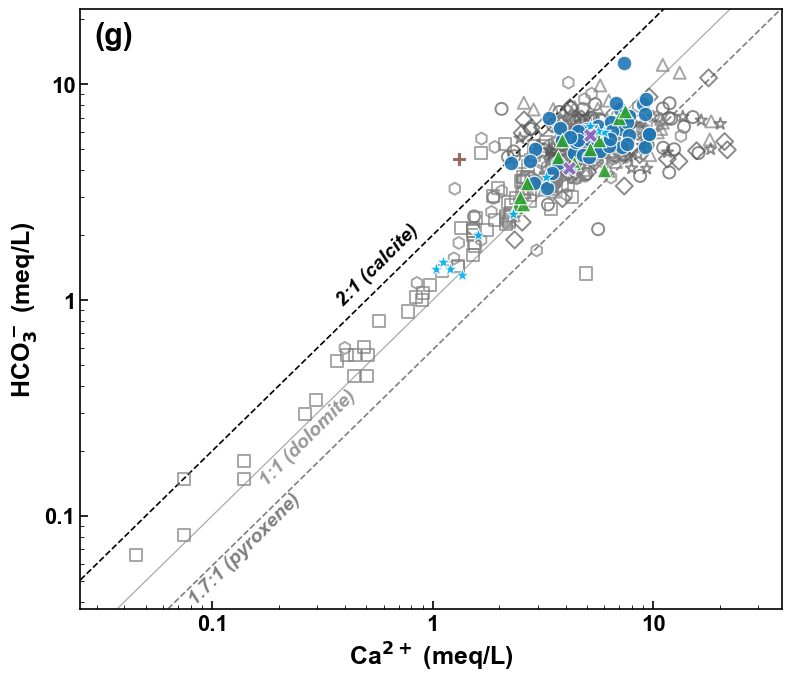

Saved: Figure4g_HCO3_vs_Ca  ->  outputs\figures\Figure4_panels
This study: 69 pts  |  Literature: 341 pts


In [11]:
# ── (g) HCO₃⁻ vs Ca²⁺  (meq/L) ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(DISPLAY_W, DISPLAY_H))

mine, lit = scatter_panel(ax, 'Ca', 'HCO3', log_scale=True)

# ── Zoom to data range ────────────────────────────────────────────────────
pad = 0.25
x_all = pd.concat([mine['Ca'], lit['Ca']]).dropna()
y_all = pd.concat([mine['HCO3'], lit['HCO3']]).dropna()
xlo = 10**(np.log10(x_all.min()) - pad)
xhi = 10**(np.log10(x_all.max()) + pad)
ylo = 10**(np.log10(y_all.min()) - pad)
yhi = 10**(np.log10(y_all.max()) + pad)
ax.set_xlim(xlo, xhi)
ax.set_ylim(ylo, yhi)

x_line = np.logspace(np.log10(xlo), np.log10(xhi), 200)

# ── Reference line 1: 1:1 (dolomite stoichiometry) ────────────────────────
ax.plot(x_line, x_line, color='#aaaaaa', ls='-', lw=0.9, zorder=1)

# ── Reference line 2: 2:1 (calcite) → HCO₃ = 2·Ca ────────────────────────
ax.plot(x_line, x_line * 2, color='black', ls='--', lw=1.2, zorder=1)

# ── Reference line 3: 1.7:1 (pyroxene) → HCO₃ = Ca / 1.7 ────────────────
ax.plot(x_line, x_line / 1.7, color='gray', ls='--', lw=1.2, zorder=1)

# ── Line labels - rotated to follow line orientation ──────────────────────
ax.text(0.36, 0.50, '2:1 (calcite)', fontsize=14, fontweight='bold', color='black',
        transform=ax.transAxes, ha='left', va='bottom', fontstyle='italic',
        rotation=45)
ax.text(0.25, 0.20, '1:1 (dolomite)', fontsize=14, fontweight='bold', color='#999999',
        transform=ax.transAxes, ha='left', va='bottom', fontstyle='italic',
        rotation=45)
ax.text(0.15, 0.0009, '1.7:1 (pyroxene)', fontsize=14, fontweight='bold', color='gray',
        transform=ax.transAxes, ha='left', va='bottom', fontstyle='italic',
        rotation=45)

# ── Axis labels ───────────────────────────────────────────────────────────
ax.set_xlabel(r'Ca$^{2+}$ (meq/L)')
ax.set_ylabel(r'HCO$_3^-$ (meq/L)')
ax.xaxis.set_major_formatter(FuncFormatter(plain_fmt))
ax.yaxis.set_major_formatter(FuncFormatter(plain_fmt))

# ── Subplot label ─────────────────────────────────────────────────────────
ax.text(0.02, 0.98, '(g)', transform=ax.transAxes, fontsize=22,
        fontweight='bold', va='top', ha='left')

save_fig(fig, DIR_PANELS, 'Figure4g_HCO3_vs_Ca')
print(f'This study: {len(mine)} pts  |  Literature: {len(lit)} pts')
COUNTS['g'] = (len(mine), len(lit))

---
### <font color='Orange'> (h) (Na⁺ + K⁺ − Cl⁻) vs (Ca²⁺ + Mg²⁺ − HCO₃⁻ − SO₄²⁻) </font>

**Interpretation:** This plot diagnoses cation exchange. A slope of −1 through the origin indicates that Na⁺+K⁺ gained equals Ca²⁺+Mg²⁺ lost (or vice versa). Upper-left quadrant (x<0, y>0): forward exchange - Na⁺ is released from clays while Ca/Mg is adsorbed. Lower-right quadrant (x>0, y<0): reverse exchange - Ca/Mg is released. Note: values can be negative - no log scale.

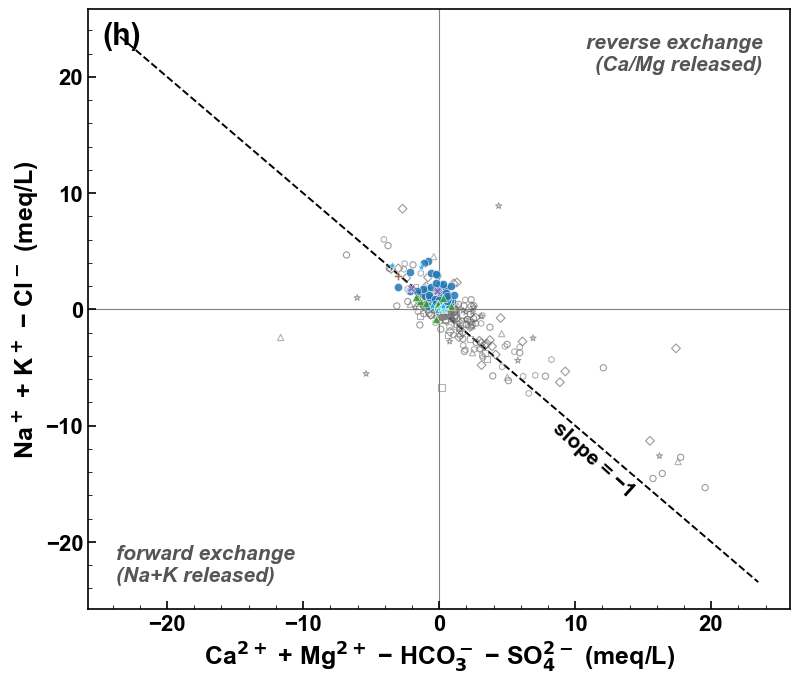

Saved: Figure4h_NaKCl_vs_CaMgHCO3SO4  ->  outputs\figures\Figure4_panels
This study: 69 pts  |  Literature: 289 pts  |  Excluded (outliers): 51


In [12]:
# ── (h) (Na⁺+K⁺−Cl⁻) vs (Ca²⁺+Mg²⁺−HCO₃⁻−SO₄²⁻)  (meq/L) ──────────────
df['NaK_Cl']        = df['Na'] + df['K'] - df['Cl']
df['CaMg_HCO3SO4']  = df['Ca'] + df['Mg'] - df['HCO3'] - df['SO4']

fig, ax = plt.subplots(figsize=(DISPLAY_W, DISPLAY_H))

# ── Exclude extreme values (|value| > 20 meq/L) so the main cloud stays readable ─
THRESHOLD = 20  # meq/L - exclude samples with |value| > 20
plot_mask = (df['NaK_Cl'].abs() <= THRESHOLD) & (df['CaMg_HCO3SO4'].abs() <= THRESHOLD)
df_plot = df[plot_mask].copy()
n_excluded = df['NaK_Cl'].notna().sum() - df_plot['NaK_Cl'].notna().sum()

# ── Manual scatter with filtered data ──────────────────────────────────────
plot_df = df_plot.dropna(subset=['CaMg_HCO3SO4', 'NaK_Cl']).copy()
plot_df = plot_df[~plot_df['Reference'].isin(NO_HYDROCHEM)]
lit  = plot_df[plot_df['Reference'] != MY_REF]
mine = plot_df[plot_df['Reference'] == MY_REF]

for ref, sty in LIT_STYLE.items():
    sub = lit[lit['Reference'] == ref]
    if sub.empty: continue
    ax.scatter(sub['CaMg_HCO3SO4'], sub['NaK_Cl'],
               marker=sty['marker'], s=20, facecolors='none',
               edgecolors=sty['color'], linewidths=0.8, alpha=0.6, zorder=2)

for typ, sty in THIS_STYLE.items():
    sub = mine[mine['Type'] == typ]
    if sub.empty: continue
    ax.scatter(sub['CaMg_HCO3SO4'], sub['NaK_Cl'],
               marker=sty['marker'], s=35, color=sty['color'],
               edgecolors='white', linewidths=0.4, alpha=0.85, zorder=3)

# ── Zero-crossing lines ───────────────────────────────────────────────────
ax.axhline(0, color='gray', lw=0.8, zorder=1)
ax.axvline(0, color='gray', lw=0.8, zorder=1)

# ── Slope = −1 through origin ─────────────────────────────────────────────
x_all = pd.concat([mine['CaMg_HCO3SO4'], lit['CaMg_HCO3SO4']]).dropna()
y_all = pd.concat([mine['NaK_Cl'], lit['NaK_Cl']]).dropna()
lim = max(abs(x_all.min()), abs(x_all.max()), abs(y_all.min()), abs(y_all.max())) * 1.2
ax.plot([-lim, lim], [lim, -lim], color='black', ls='--', lw=1.4, zorder=1)

# ── Line label - bottom-right, clear area ─────────────────────────────────
ax.text(0.72, 0.18, 'slope = −1', fontsize=15, fontweight='bold', color='black',
        rotation=-42, transform=ax.transAxes, ha='center', va='bottom')

# ── Quadrant labels - corners away from data ──────────────────────────────
ax.text(0.04, 0.04, 'forward exchange\n(Na+K released)', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='left', va='bottom')
ax.text(0.96, 0.96, 'reverse exchange\n(Ca/Mg released)', transform=ax.transAxes,
        fontsize=15, fontweight='bold', fontstyle='italic', color='#555555', ha='right', va='top')

# ── Axis labels ───────────────────────────────────────────────────────────
ax.set_xlabel(r'Ca$^{2+}$ + Mg$^{2+}$ − HCO$_3^-$ − SO$_4^{2-}$ (meq/L)')
ax.set_ylabel(r'Na$^+$ + K$^+$ − Cl$^-$ (meq/L)')

# ── Subplot label ─────────────────────────────────────────────────────────
ax.text(0.02, 0.98, '(h)', transform=ax.transAxes, fontsize=22,
        fontweight='bold', va='top', ha='left')

save_fig(fig, DIR_PANELS, 'Figure4h_NaKCl_vs_CaMgHCO3SO4')
print(f'This study: {len(mine)} pts  |  Literature: {len(lit)} pts  |  Excluded (outliers): {n_excluded}')
COUNTS['h'] = (len(mine), len(lit))

### <font color='orange'> **6) Shared legend (bottom-right tile of Figure 4)** </font>

Saved: Figure4_legend  ->  outputs\figures\Figure4_panels
Legend: balanced size, fits one panel


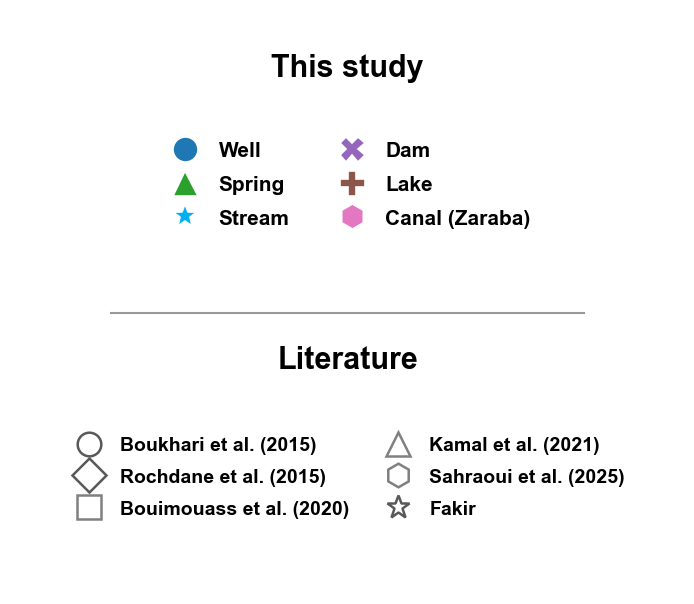

6

In [13]:
# ── Standalone legend - balanced size, fits one panel ─────────────────
fig_leg, ax_leg = plt.subplots(figsize=(FIG_W, FIG_H))
ax_leg.set_xlim(0, 1)
ax_leg.set_ylim(0, 1)
ax_leg.axis('off')

# Section A - This study (filled markers)
this_handles = [
    mlines.Line2D([], [], marker=sty['marker'], color=sty['color'],
                  markeredgecolor='white', markeredgewidth=1.2,
                  markersize=18, linestyle='None', label=sty['label'])
    for typ, sty in THIS_STYLE.items()
    if typ in df.loc[df['Reference'] == MY_REF, 'Type'].values
]

# Section B - Literature (open markers)
lit_handles = [
    mlines.Line2D([], [], marker=sty['marker'], color='none',
                  markeredgecolor=sty['color'], markeredgewidth=1.8,
                  markersize=17, linestyle='None', label=sty['label'])
    for ref, sty in LIT_STYLE.items()
    if ref in df['Reference'].values
]

# ── "This study" title ──────────────────────────────────────────
ax_leg.text(0.5, 0.90, 'This study', transform=ax_leg.transAxes,
            fontsize=22, fontweight='bold', ha='center', va='center')

# This study markers - 2 cols x 3 rows
leg1 = ax_leg.legend(handles=this_handles,
                     loc='center', bbox_to_anchor=(0.5, 0.70),
                     ncol=2, fontsize=15,
                     frameon=False, handletextpad=0.6,
                     columnspacing=2.0, labelspacing=0.7)
for text in leg1.get_texts():
    text.set_fontweight('bold')
ax_leg.add_artist(leg1)

# ── Separator line ──────────────────────────────────────────────
ax_leg.axhline(0.48, xmin=0.15, xmax=0.85, color='#999999', lw=1.5)

# ── "Literature" title ─────────────────────────────────────────
ax_leg.text(0.5, 0.40, 'Literature', transform=ax_leg.transAxes,
            fontsize=22, fontweight='bold', ha='center', va='center')

# Literature markers - 2 cols x 3 rows
leg2 = ax_leg.legend(handles=lit_handles,
                     loc='center', bbox_to_anchor=(0.5, 0.20),
                     ncol=2, fontsize=14,
                     frameon=False, handletextpad=0.6,
                     columnspacing=1.5, labelspacing=0.7)
for text in leg2.get_texts():
    text.set_fontweight('bold')

# ── Export ───────────────────────────────────────────────────────
fig_leg.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)

for fmt in ['png']:
    fig_leg.savefig(DIR_PANELS / f'Figure4_legend.{fmt}',
                    format=fmt, dpi=EXPORT_DPI,
                    facecolor='white')
print(f'Saved: Figure4_legend  ->  {DIR_PANELS.relative_to(ROOT)}')
print(f'Legend: balanced size, fits one panel')
plt.show()
plt.close(fig_leg)
gc.collect()

### <font color='orange'> **7) Check against the published figure** </font>

Number of points (this study, literature) in each panel of the published Figure 4.

In [14]:
EXPECTED = {"a": (69, 340), "b": (69, 341), "c": (69, 338), "d": (69, 340),
            "e": (69, 338), "f": (59, 298), "g": (69, 341), "h": (69, 289)}
for k, v in EXPECTED.items():
    print(f"  ({k}) this study {COUNTS[k][0]:3d} | literature {COUNTS[k][1]:3d}   expected {v}")
assert COUNTS == EXPECTED, "point counts differ from the published Figure 4"
print("\n✓ All 8 panels plot the same samples as the published Figure 4.")

  (a) this study  69 | literature 340   expected (69, 340)
  (b) this study  69 | literature 341   expected (69, 341)
  (c) this study  69 | literature 338   expected (69, 338)
  (d) this study  69 | literature 340   expected (69, 340)
  (e) this study  69 | literature 338   expected (69, 338)
  (f) this study  59 | literature 298   expected (59, 298)
  (g) this study  69 | literature 341   expected (69, 341)
  (h) this study  69 | literature 289   expected (69, 289)

✓ All 8 panels plot the same samples as the published Figure 4.


---
**Figures:** `outputs/figures/Figure4_panels/` (8 panels + legend, assembled as Figure 4), `outputs/figures/SM01_CaMg_ratio_vs_Ca`, `outputs/figures/SM02_CAI_indices`

**Next:** `03_PCA_SOM_HCA/01_PCA_SOM_training.ipynb` (PCA, SOM training; Figure 5, SM3-SM6)